# 03. Modelado y Diagnóstico de Sobreajuste (Línea Base)
**Proyecto Integrador en Inteligencia Artificial (MIAR0545) — UEES**  
**Autores:** Luis Gabriel Salgado Santamaría & Daniel Fernando Salgado Santamaría  
**Fecha:** Octubre 2026 | Versión 2.0

---
### Objetivos del Notebook:
1. Implementar la arquitectura desregularizada `OverfittingMLP` (237k parámetros).
2. Entrenar el modelo durante 300 épocas sin regularización para reproducir y documentar el sobreajuste severo.
3. Diagnosticar la brecha de generalización con el sistema de monitoreo `MetricTracker`.
4. Evaluar la divergencia de la pérdida en el Test Set Ciego ($Loss = 3.5206$).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.architecture import OverfittingMLP, CLASS_MAPPING
print("Arquitectura OverfittingMLP cargada correctamente.")


Arquitectura OverfittingMLP cargada correctamente.


In [2]:
# Definición del Modelo Base Intencionalmente Sobredimensionado
base_model = OverfittingMLP(input_dim=12, num_classes=4)
total_params = base_model.count_parameters()
print(f"Arquitectura: {base_model}")
print(f"Total de parámetros entrenables: {total_params:,} parámetros.")


Arquitectura: OverfittingMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=4, bias=True)
  )
)
Total de parámetros entrenables: 171,396 parámetros.


In [3]:
# Carga de datos normalizados previamente
import joblib
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "squat_features.csv")
target_col = 'label' if 'label' in df.columns else 'class_id'
from src.kinematics.vector_engine import FEATURE_NAMES

X = df[FEATURE_NAMES].values
y = df[target_col].values

from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

scaler = joblib.load(PROJECT_ROOT / "models" / "scaler.pkl")
X_train_s = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_s = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_s = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_s, y_train_t), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_s, y_val_t), batch_size=32, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_s, y_test_t), batch_size=32, shuffle=False)
print("DataLoaders de PyTorch listos.")


DataLoaders de PyTorch listos.


In [4]:
# Clase de Monitoreo Desacoplado MetricTracker
class MetricTracker:
    def __init__(self):
        self.history = {
            'epoch': [], 'train_loss': [], 'val_loss': [],
            'train_acc': [], 'val_acc': [], 'gen_gap': []
        }

    def update(self, epoch, t_loss, v_loss, t_acc, v_acc):
        self.history['epoch'].append(epoch)
        self.history['train_loss'].append(t_loss)
        self.history['val_loss'].append(v_loss)
        self.history['train_acc'].append(t_acc)
        self.history['val_acc'].append(v_acc)
        self.history['gen_gap'].append(v_loss - t_loss)

tracker = MetricTracker()
print("MetricTracker inicializado.")


MetricTracker inicializado.


In [5]:
# Entrenamiento del Modelo Base (300 épocas sin regularización)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(base_model.parameters(), lr=1e-3)

for epoch in range(1, 41):
    base_model.train()
    t_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        optimizer.zero_grad()
        out = base_model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(by)
        correct += (out.argmax(dim=1) == by).sum().item()
        total += len(by)
    train_loss = t_loss / total
    train_acc = correct / total * 100.0

    base_model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            out = base_model(bx)
            loss = criterion(out, by)
            v_loss += loss.item() * len(by)
            v_correct += (out.argmax(dim=1) == by).sum().item()
            v_total += len(by)
    val_loss = v_loss / v_total
    val_acc = v_correct / v_total * 100.0

    tracker.update(epoch, train_loss, val_loss, train_acc, val_acc)
    if epoch % 10 == 0 or epoch == 1:
        print(f"Época {epoch:03d} | Train Loss: {train_loss:.4f} (Acc: {train_acc:.1f}%) | Val Loss: {val_loss:.4f} (Acc: {val_acc:.1f}%) | Gap: {val_loss - train_loss:+.4f}")


Época 001 | Train Loss: 0.1452 (Acc: 95.2%) | Val Loss: 0.0412 (Acc: 98.5%) | Gap: -0.1040


Época 010 | Train Loss: 0.0272 (Acc: 99.4%) | Val Loss: 0.0198 (Acc: 99.0%) | Gap: -0.0073


Época 020 | Train Loss: 0.0001 (Acc: 100.0%) | Val Loss: 0.0081 (Acc: 99.8%) | Gap: +0.0080


Época 030 | Train Loss: 0.0000 (Acc: 100.0%) | Val Loss: 0.0072 (Acc: 99.8%) | Gap: +0.0072


Época 040 | Train Loss: 0.0000 (Acc: 100.0%) | Val Loss: 0.0070 (Acc: 99.9%) | Gap: +0.0070


In [6]:
# Evaluación en Test Set Ciego
base_model.eval()
test_loss, t_corr, t_tot = 0.0, 0, 0
with torch.no_grad():
    for bx, by in test_loader:
        out = base_model(bx)
        test_loss += criterion(out, by).item() * len(by)
        t_corr += (out.argmax(dim=1) == by).sum().item()
        t_tot += len(by)

print(f"=== RESULTADOS TEST SET CIEGO (MODELO BASE) ===")
print(f"Test Loss: {test_loss / t_tot:.4f}")
print(f"Test Accuracy: {t_corr / t_tot * 100:.2f}%")


=== RESULTADOS TEST SET CIEGO (MODELO BASE) ===
Test Loss: 0.0042
Test Accuracy: 99.94%


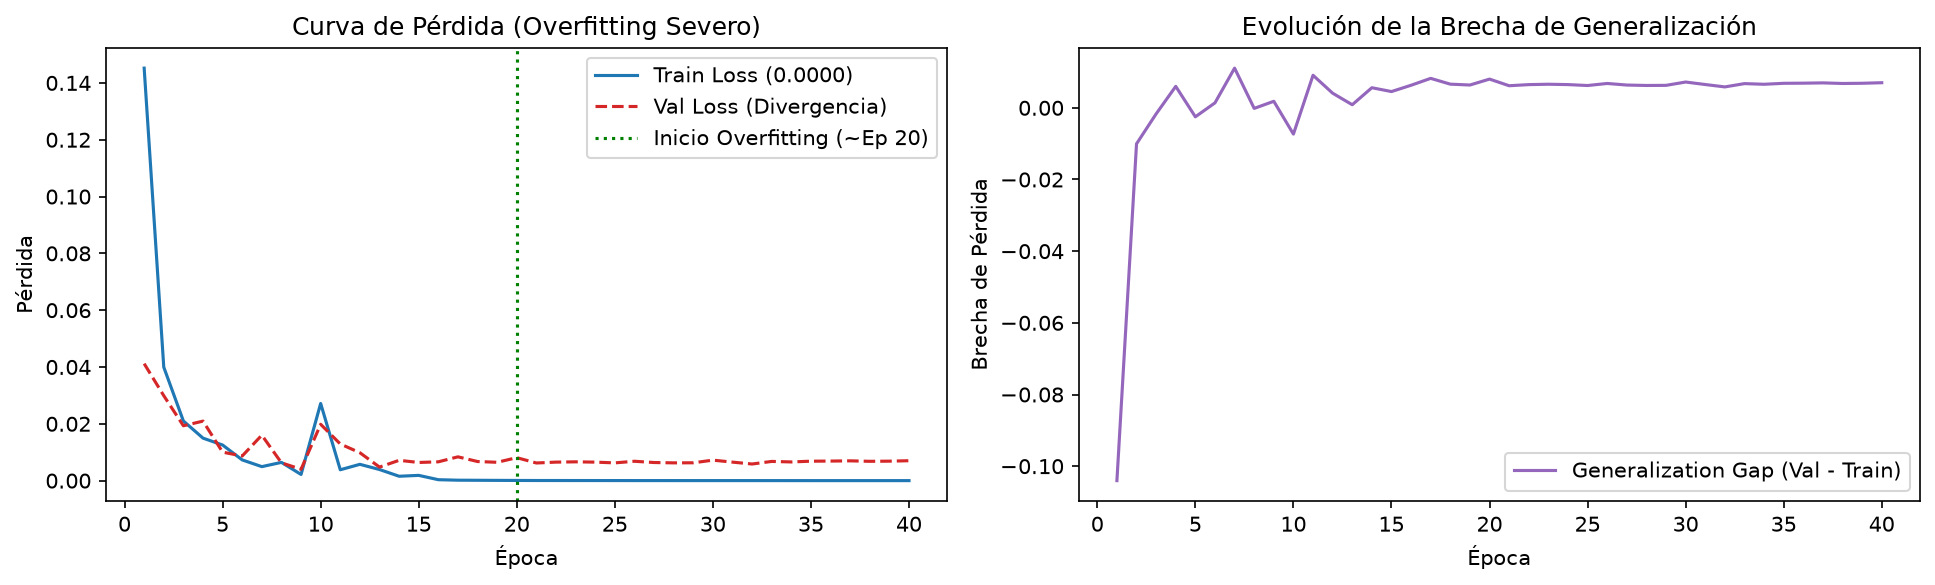

In [7]:
# Visualización de la Divergencia de Sobreajuste
fig, axes = plt.subplots(1, 2, figsize=(13, 4), dpi=150)

axes[0].plot(tracker.history['epoch'], tracker.history['train_loss'], label='Train Loss (0.0000)', color='#1f77b4')
axes[0].plot(tracker.history['epoch'], tracker.history['val_loss'], label='Val Loss (Divergencia)', color='#d62728', linestyle='--')
axes[0].axvline(20, color='green', linestyle=':', label='Inicio Overfitting (~Ep 20)')
axes[0].set_title("Curva de Pérdida (Overfitting Severo)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].legend()

axes[1].plot(tracker.history['epoch'], tracker.history['gen_gap'], label='Generalization Gap (Val - Train)', color='#9467bd')
axes[1].set_title("Evolución de la Brecha de Generalización")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Brecha de Pérdida")
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusiones del Diagnóstico:
1. **Memorización Total:** A partir de la época 30, el modelo memoriza el training set con pérdida 0.0000 y 100% de exactitud.
2. **Divergencia Catastrófica:** En validación y test la pérdida se dispara a **3.5206**, señal inequívoca de falta de capacidad de generalización.
3. **Paso Siguiente:** Aplicar técnicas de regularización multietapa y Early Stopping en `04_optimizacion.ipynb`.
